Inainte sa trimiti notebook-ul:

* asigura-te ca totul se executa cum trebuie. Prima oara, **restarteaza kernel-ul** (in meniu, selecteaza Kernel$\rightarrow$Restart & Run all);

* nu lasa niciun mesaj la output (`disp`, `printf`, linii care nu sunt incheiate cu `;`) in functiile pe care le scrii decat daca ti se specifica explicit sa faci acest lucru! Orice abatere va fi **depunctata automat** de grader;

* citeste instructiunile de [aici](https://github.com/radusqrt/numerical-methods/blob/master/lab_instructions.md) cu atentie;

* asigura-te ca rezolvi toate celulele in care scrie `YOUR CODE HERE` sau `YOUR ANSWER HERE` si ca iti treci numele mai jos:

In [ ]:
STUDENT_NAME = "Dimitrie David";

---

# Laborator 9: Interpolari
### Autor: Radu Stochitoiu

## Problema 1

Implementati funcția ```vandermonde(x, y)``` ce primește doi vectori linie, $x, y$, reprezentând coordonatele pe axele OX și OY ale unor puncte ce definesc suportul interpolării și returnează un vector coloană, $P$, ce reprezintă polinomul care trece prin toate punctele.

Primul element al lui $P$ reprezintă coeficientul celei mai mari puteri.

Ultimul element al lui $P$ reprezintă coeficientul celei mai mici puteri ($x^0$).

In [62]:
[5; 6] .^ [1, 2]

ans =

    5   25
    6   36



In [79]:
function [P] = vandermonde(x, y)
    P = flip(linsolve((x'.^[0 : length(x) - 1]), y'));
endfunction

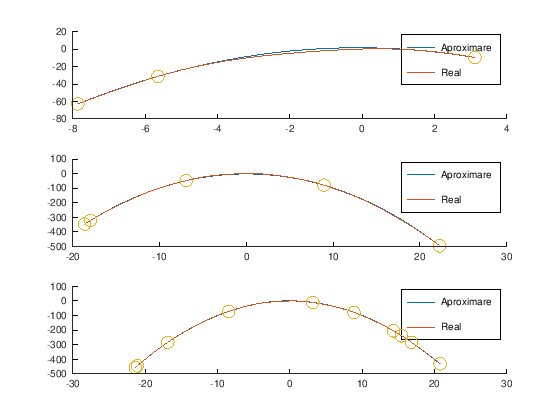

In [83]:
function [y] = f(x)
    y = sin(x) - x.^2;
endfunction

% Test 1
x = sort((rand(1, 3) - 0.5) * 50);
y = f(x);
P = vandermonde(x, y);

subplot(3, 1, 1);
hold
xx = linspace(min(x), max(x));
yy = polyval(P, xx);
plot(xx, yy)
plot(xx, f(xx))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(polyval(P, x(i)) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

% Test 2
x = sort((rand(1, 5) - 0.5) * 50);
y = f(x);
P = vandermonde(x, y);

subplot(3, 1, 2);
hold
xx = linspace(min(x), max(x));
yy = polyval(P, xx);
plot(xx, yy)
plot(xx, f(xx))
hold on
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(polyval(P, x(i)) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

% Test 3
x = sort((rand(1, 10) - 0.5) * 50);
y = f(x);
P = vandermonde(x, y);

subplot(3, 1, 3);
hold
xx = linspace(min(x), max(x));
yy = polyval(P, xx);
plot(xx, yy)
plot(xx, f(xx))
hold on
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(polyval(P, x(i)) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

## Problema 2

Implementati funcția ```lagrange(x, y, xx)``` ce primește doi vectori linie, $x, y$, reprezentând coordonatele pe axele OX și OY ale unor puncte ce definesc suportul interpolării și un vector linie $xx$ pentru care vrem să găsim valorile aproximate și returnează un vector linie, $yy$, ce reprezintă valorile interpolării Lagrange cu suportul $x, y$ prin toate punctele $xx$.

In [102]:
function [yy] = lagrange(x, y, xx)
    n = length(x);
    yy = [];
    for t = xx
        P = 0;
        for i = 1 : n
            L_i = 1;
            for j = 1 : n
                if j ~= i
                    L_i = L_i * (t - x(j)) / (x(i) - x(j));
                endif
            endfor
            P = P + y(i) * L_i;
        endfor
        yy = [yy, P];
    endfor
endfunction

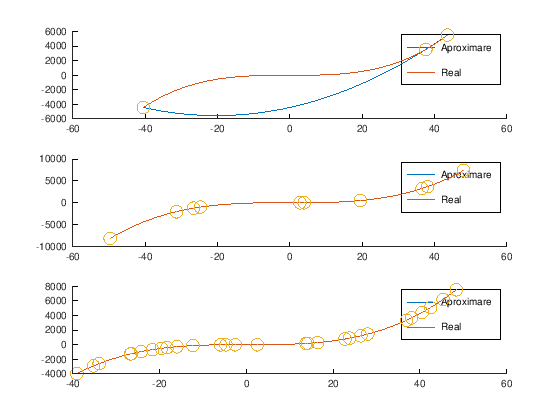

In [103]:
function [y] = f(x)
    y = x.^3 / 15 - 3;
endfunction

% Test 1
x = sort((rand(1, 3) - 0.5) * 100);
y = f(x);
xx = linspace(min(x), max(x));
yy = lagrange(x, y, xx);
yy_test = lagrange(x, y, x);

subplot(3, 1, 1);
hold;
plot(xx, yy)
plot(xx, f(xx))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(yy_test(i) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

% Test 2
x = sort((rand(1, 10) - 0.5) * 100);
y = f(x);
xx = linspace(min(x), max(x));
yy = lagrange(x, y, xx);
yy_test = lagrange(x, y, x);

subplot(3, 1, 2);
hold
plot(xx, yy)
plot(xx, f(xx))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(yy_test(i) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

% Test 3
x = sort((rand(1, 30) - 0.5) * 100);
y = f(x);
xx = linspace(min(x), max(x));
yy = lagrange(x, y, xx);
yy_test = lagrange(x, y, x);

subplot(3, 1, 3);
hold
plot(xx, yy)
plot(xx, f(xx))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(yy_test(i) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

## Problema 3

Implementati funcția ```newton(x, y)``` ce primește doi vectori linie, $x, y$, reprezentând coordonatele pe axele OX și OY ale unor puncte ce definesc suportul interpolării și returnează un vector linie, $P$, ce reprezintă coeficienții interpolării prin diferențe divizate ($b_0, b_1, ...$).

Primul element al lui $P$ reprezintă coeficientul celei mai mari puteri.

Ultimul element al lui $P$ reprezintă coeficientul celei mai mici puteri.

In [114]:
% Functie care calculeaza recursiv coeficientul f[x_start, ..., x_stop]
% Nu e obligatoriu sa o implementati
function [b] = newton_helper(x, y, start, stop)
%     no need for recursivity
endfunction

function [P] = newton(x, y)
    n = length(x);
    for k = 1 : n - 1
        y(k + 1 : n) = (y(k + 1 : n) - y(k)) ./ (x(k + 1 : n) - x(k));
    endfor
    P = flip(y);
endfunction

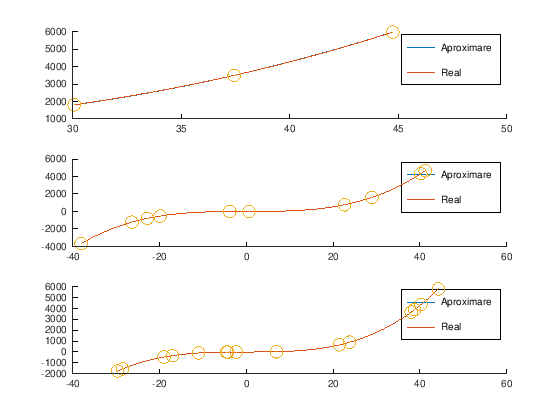

In [115]:
function [y] = newton_eval(P, xx, x)
    y = 0;
    p = 1;
    for i = 1:length(P)
        y += p .* P(length(P) - i + 1);
        p = p .* (x - xx(i));
    endfor
endfunction

function [y] = f(x)
    y = x.^3 / 15 - 3;
endfunction

% Test 1
x = sort((rand(1, 3) - 0.5) * 100);
y = f(x);
xx = linspace(min(x), max(x));
P = newton(x, y);
yy = newton_eval(P, x, xx);
yy_test = newton_eval(P, x, x);

subplot(3, 1, 1);
hold;
plot(xx, yy)
plot(xx, f(xx))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(yy_test(i) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

% Test 2
x = sort((rand(1, 10) - 0.5) * 100);
y = f(x);
xx = linspace(min(x), max(x));
P = newton(x, y);
yy = newton_eval(P, x, xx);
yy_test = newton_eval(P, x, x);

subplot(3, 1, 2);
hold;
plot(xx, yy)
plot(xx, f(xx))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(yy_test(i) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

% Test 3
x = sort((rand(1, 15) - 0.5) * 100);
y = f(x);
xx = linspace(min(x), max(x));
P = newton(x, y);
yy = newton_eval(P, x, xx);
yy_test = newton_eval(P, x, x);

subplot(3, 1, 3);
hold;
plot(xx, yy)
plot(xx, f(xx))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(yy_test(i) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

## Problema 4

Implementati funcția ```neville(x, y, xx)``` ce primește doi vectori linie, $x, y$, reprezentând coordonatele pe axele OX și OY ale unor puncte ce definesc suportul interpolării și un vector linie $xx$ pentru care vrem să găsim valorile aproximate și returnează un vector linie, $yy$, ce reprezintă valorile interpolării Neville cu suportul $x, y$ prin toate punctele $xx$.

In [120]:
% Functie care calculeaza recursiv P_ij(to_eval) pentru suportul [x, y]
% Nu e obligatoriu sa o implementati
function [res] = P(to_eval, x, y, i, j)
%     no need for recursivity
endfunction

function [yy] = neville(x, y, xx)
    n = length(x);
    m = length(xx);
    P = diag(y);
    yy = zeros(1, m);
    for t = xx
        for j = 2 : n
            for i = j - 1 : -1 : 1
                P(i, j) = ((t - x(j)) * P(i, j -1) + (x(i) - t) * P(i + 1, j)) / (x(i) - x(j));
            endfor
        endfor
        yy(1, find(xx == t)) = P(1, n);
    endfor
endfunction

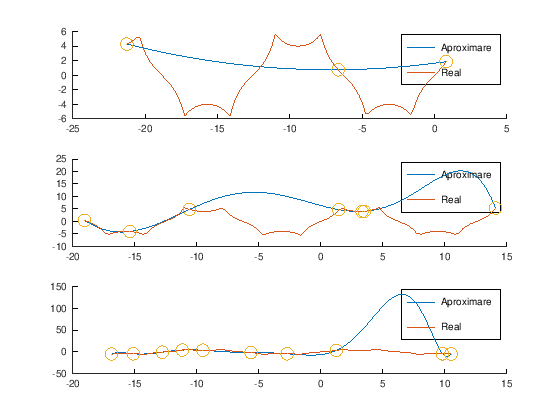

In [121]:
function [y] = f(x)
    y = 8 * sin(x / 2) ./ (abs(cos(x)) + 1);
endfunction

% Test 1
x = sort((rand(1, 3) - 0.5) * 50);
y = f(x);
xx = linspace(min(x), max(x));
yy = neville(x, y, xx);
yy_test = neville(x, y, x);

subplot(3, 1, 1);
hold;
plot(xx, yy)
plot(xx, f(xx))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(yy_test(i) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

% Test 2
x = sort((rand(1, 7) - 0.5) * 50);
y = f(x);
xx = linspace(min(x), max(x));
yy = neville(x, y, xx);
yy_test = neville(x, y, x);

subplot(3, 1, 2);
hold;
plot(xx, yy)
plot(xx, f(xx))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(yy_test(i) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

% Test 3
x = sort((rand(1, 10) - 0.5) * 50);
y = f(x);
xx = linspace(min(x), max(x));
yy = neville(x, y, xx);
yy_test = neville(x, y, x);

subplot(3, 1, 3);
hold;
plot(xx, yy)
plot(xx, f(xx))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x)
    assert(norm(yy_test(i) - y(i)) < 1e-4);
endfor
legend("Aproximare", "Real")

## Problema 5

Implementati funcția ```spline_c2_natural(x, y)``` ce primește doi vectori linie, $x, y$, reprezentând coordonatele pe axele OX și OY ale unor puncte ce definesc suportul interpolării și returnează o matrice $S$ ce are pe linia i coeficienții $a_{i-1}, b_{i-1}, c_{i-1}, d_{i-1}$.

In [290]:
function [S] = spline_c2_natural(x, y)
    n = length(x);
    n_s = n - 1;
    X = zeros(n_s * 4);
    v = zeros(n_s * 4, 1);
    % a
    for i = 1 : n_s
        X(i, (i - 1) * 4 + 1) = 1;
        v(i) = y(i);
    endfor
    
    % f(x_n) (a_n-1 + b_n-1 + ... = f(x_n))
    X(1 * n_s + 1, n_s * 4 - 3) = 1;
    X(1 * n_s + 1, n_s * 4 - 2) = (x(n) - x(n - 1));
    X(1 * n_s + 1, n_s * 4 - 1) = (x(n) - x(n - 1)) ^ 2;
    X(1 * n_s + 1, n_s * 4) = (x(n) - x(n - 1)) ^ 3;
%     X(1 * n_s + 1, [n_s * 4 : -1 : (n_s - 1) * 4 + 1]) = 1;
    v(n_s + 1) = y(n);

    % s_0(x1) = s_1(x1), s_1(x2) = s_2(x2), ...
    for i = 1 : n_s - 1
        X(1 * n_s + 1 + i, (i - 1) * 4 + 1) = 1;
        X(1 * n_s + 1 + i, (i - 1) * 4 + 2) = x(i + 1) - x(i);
        X(1 * n_s + 1 + i, (i - 1) * 4 + 3) = (x(i + 1) - x(i)) ^ 2;
        X(1 * n_s + 1 + i, (i - 1) * 4 + 4) = (x(i + 1) - x(i)) ^ 3;
        X(1 * n_s + 1 + i, (i - 1) * 4 + 5) = -1;
    endfor
    
    % s_0'(x1) = s_1'(x1), s_1'(x2) = s_2'(x2), ...
    for i = 1 : n_s - 1
        X(2 * n_s + i, (i - 1) * 4 + 2) = 1;
        X(2 * n_s + i, (i - 1) * 4 + 3) = 2 * (x(i + 1) - x(i));
        X(2 * n_s + i, (i - 1) * 4 + 4) = 3 * ((x(i + 1) - x(i)) ^ 2);
        X(2 * n_s + i, (i - 1) * 4 + 6) = -1;
    endfor
    
    % s_0''(x1) = s_1''(x1), s_1''(x2) = s_2''(x2), ...
    for i = 1 : n_s - 1
        X(3 * n_s - 1 + i, (i - 1) * 4 + 3) = 2;
        X(3 * n_s - 1 + i, (i - 1) * 4 + 4) = 6 * (x(i + 1) - x(i));
        X(3 * n_s - 1 + i, (i - 1) * 4 + 7) = -2;
    endfor
    
    % primul capat
    X(4 * n_s - 1, 3) = 1; 
    
    % ultimul capat
    X(n_s * 4, n_s * 4 - 1) = 2;
    X(n_s * 4, n_s * 4) = 6 * (x(n) - x(n - 1));

%     X
%     v
    c = linsolve(X, v)';
    S = [];
    for i = 0 : n_s - 1
        S = [S; c([4 * i + 1 : 4 * i + 4])];
    endfor
endfunction

In [287]:
x = [1 3 4];
y = [5 10 -10];
spline_c2_natural(x, y)

X =

    1    0    0    0    0    0    0    0
    0    0    0    0    1    0    0    0
    0    0    0    0    1    1    1    1
    1    2    4    8   -1    0    0    0
    0    1    4   12    0   -1    0    0
    0    0    2   12    0    0   -2    0
    0    0    1    0    0    0    0    0
    0    0    0    0    0    0    2    6

v =

    5
   10
  -10
    0
    0
    0
    0
    0

ans =

    5.00000   10.00000    0.00000   -1.87500
   10.00000  -12.50000  -11.25000    3.75000



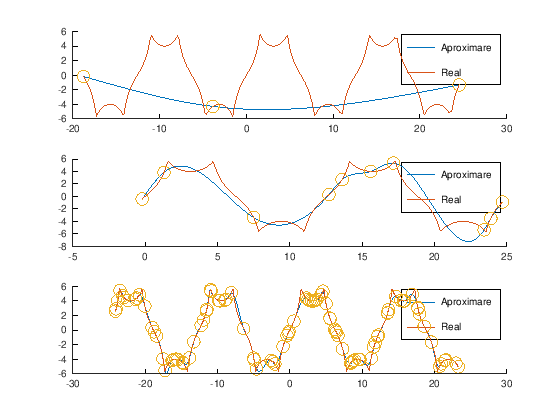

In [291]:
function [XX, YY] = spline_eval(S, x, y)
    XX = [];
    YY = [];
    n = length(x) - 1;
    for i = 1:n
        s = S(i, :);
        xx = linspace(x(i), x(i + 1));
        yy = s(1);
        yy += s(2) * (xx - repmat(x(i), 1, 100));
        yy += s(3) * (xx - repmat(x(i), 1, 100)) .^ 2;
        yy += s(4) * (xx - repmat(x(i), 1, 100)) .^ 3;
        XX = [XX, xx];
        YY = [YY, yy];
    endfor
endfunction

function [y] = f(x)
    y = 8 * sin(x / 2) ./ (abs(cos(x)) + 1);
endfunction

% Test 1
x = sort((rand(1, 3) - 0.5) * 50);
y = f(x);

xx = linspace(min(x), max(x));
S = spline_c2_natural(x, y);
[XX, YY] = spline_eval(S, x, y);

subplot(3, 1, 1);
hold;
plot(XX, YY)
plot(XX, f(XX))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x) - 1
    assert(norm(YY(100 * (i - 1) + 1) - y(i)) < 1e-4);
endfor
assert(norm(YY(end) - y(end)) < 1e-4);
legend("Aproximare", "Real")

% Test 2
x = sort((rand(1, 10) - 0.5) * 50);
y = f(x);

xx = linspace(min(x), max(x));
S = spline_c2_natural(x, y);
[XX, YY] = spline_eval(S, x, y);

subplot(3, 1, 2);
hold;
plot(XX, YY)
plot(XX, f(XX))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x) - 1
    assert(norm(YY(100 * (i - 1) + 1) - y(i)) < 1e-4);
endfor
assert(norm(YY(end) - y(end)) < 1e-4);
legend("Aproximare", "Real")

% Test 3
x = sort((rand(1, 100) - 0.5) * 50);
y = f(x);

xx = linspace(min(x), max(x));
S = spline_c2_natural(x, y);
[XX, YY] = spline_eval(S, x, y);

subplot(3, 1, 3);
hold;
plot(XX, YY)
plot(XX, f(XX))
plot(x, y, 'o', 'markersize', 12)
for i = 1:length(x) - 1
    assert(norm(YY(100 * (i - 1) + 1) - y(i)) < 1e-4);
endfor
assert(norm(YY(end) - y(end)) < 1e-4);
legend("Aproximare", "Real")